# Colab run — saved evidence

Saved outputs from the run reported on 2026-10-14. No training or test was rerun for publication. Interpretive Markdown was corrected against the saved tables; the final test flag is reset to False for safe viewing. For a clean run use `chapter_01.ipynb`. The checkpoints referenced in this snapshot are not included.


# Homework 1 — Learning from Little Data
**Deep Learning for Computer Vision · Chapter 1**

You get only **500 labelled images per digit** from MNIST (5,000 in total). Every other image (65,000) is the test set.
The question for this homework: **how can a CNN trained on so little data still generalise well?**

Only the data loading is given. Everything else — model, training loop, plots — you write yourself.

**Rules.**
- Use the **validation set** to compare ideas. The test set is used **once**, in Step 5.
- Steps 2–4 are open: come up with your own ideas and try them. There is no single right answer.
- Answer each question briefly (1–3 sentences) in a markdown cell below the step.

## Cách chạy — thực nghiệm mới từ đầu

**Lê Hải Bình — Homework 1.** Notebook chưa được huấn luyện hoặc đánh giá test. Không có cache, model, số liệu hay hình từ lượt cũ; tất cả kết quả được tạo khi chạy code.

Chạy các cell từ trên xuống. Steps 1–4 chỉ dùng train/validation; chọn recipe bằng mean validation accuracy qua ba seed, rồi dùng seed 0 cố định. Các checkpoint và lịch sử tự lưu trong thư mục output; không cần chuẩn bị file kết quả bên ngoài.

Step 1: baseline 180 epoch LR cố định. Steps 2–4: cosine 60 epoch, ba seed. Learning curve tốn thêm thời gian. Nếu baseline chưa overfit rõ, quan sát đồ thị và điều chỉnh ngân sách chỉ với train/validation.

**Step 5:** sau khi chốt model từ validation, đổi `RUN_STEP5=True` trong cell cuối để đánh giá test một lần. Không thay model dựa vào kết quả test. Câu trả lời đang là hướng dẫn điền; cập nhật bằng số liệu thực tế của lượt mới.


In [1]:
# ============================================================
#  DATA LOADING — given. DO NOT MODIFY THIS CELL.
# ============================================================
import numpy as np, torch, torchvision
from sklearn.model_selection import train_test_split


def load_mnist_small(per_class=500, val_frac=0.1, seed=0):
    # 1. Download MNIST and merge the official train (60k) and test (10k)
    #    into one pool of 70k images. Pixels are scaled to [0, 1] and given
    #    a channel axis: X has shape N x 1 x 28 x 28, y has shape N.
    tr = torchvision.datasets.MNIST('./data', train=True, download=True)
    te = torchvision.datasets.MNIST('./data', train=False, download=True)
    X = torch.cat([tr.data, te.data]).float().div(255).unsqueeze(1)
    y = torch.cat([tr.targets, te.targets])

    # 2. For each digit k = 0..9, shuffle its indices with a fixed seed,
    #    so everyone gets exactly the same split.
    g = torch.Generator().manual_seed(seed)
    idx = [torch.nonzero(y == k).squeeze(1) for k in range(10)]
    idx = [i[torch.randperm(len(i), generator=g)] for i in idx]

    # 3. Take the first `per_class` images of each digit as the labelled
    #    pool (500 x 10 = 5,000). All remaining images form the test set.
    pool = torch.cat([i[:per_class] for i in idx])
    test = torch.cat([i[per_class:] for i in idx])

    # 4. Split the labelled pool into train / validation with stratified
    #    sampling: every digit keeps the same proportion (90% / 10%)
    #    in both parts, so the validation set is balanced too.
    tr_i, va_i = train_test_split(pool.numpy(), test_size=val_frac,
                                  stratify=y[pool].numpy(),
                                  random_state=seed)
    tr_i, va_i = torch.from_numpy(tr_i), torch.from_numpy(va_i)

    # 5. Return (images, labels) for train, validation and test.
    return (X[tr_i], y[tr_i]), (X[va_i], y[va_i]), (X[test], y[test])


(x_tr, y_tr), (x_va, y_va), (x_te, y_te) = load_mnist_small()

# Sanity check: number of images and count per digit in each split.
for name, t in [('train', y_tr), ('val', y_va), ('test', y_te)]:
    print(f'{name:5s}', len(t), torch.bincount(t, minlength=10).tolist())

train 4500 [450, 450, 450, 450, 450, 450, 450, 450, 450, 450]
val   500 [50, 50, 50, 50, 50, 50, 50, 50, 50, 50]
test  65000 [6403, 7377, 6490, 6641, 6324, 5813, 6376, 6793, 6325, 6458]


# **Khung chung — model, vòng huấn luyện và trình bày kết quả**
Loss ghi nhận sau mỗi epoch là cross-entropy nhãn thật trên ảnh sạch, kể cả khi loss tối ưu có label smoothing. Chỉ hàm train/validation được cung cấp ở đây; không có đánh giá test tự động.

In [2]:
import json, math, time, hashlib
from datetime import datetime
from pathlib import Path
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

RUN_DIR = Path("hw1_runs") / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
RUN_DIR.mkdir(parents=True, exist_ok=True)
print("Output directory:", RUN_DIR)

DEV = ("cuda" if torch.cuda.is_available() else
       "mps" if torch.backends.mps.is_available() else "cpu")
print("Device:", DEV)

def seed_all(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

class Pool3(nn.Module):
    # Adaptive average pool 7×7 → 3×3, tương đương bins PyTorch.
    # Dùng mean/stack để hỗ trợ MPS.
    def forward(self, x):
        H, W = x.shape[-2:]
        return torch.stack([
            torch.stack([
                x[..., i*H//3:((i+1)*H+2)//3,
                  j*W//3:((j+1)*W+2)//3].mean((-2,-1))
                for j in range(3)], dim=-1)
            for i in range(3)], dim=-2)

class CNN(nn.Module):
    def __init__(self, width=32, head="flatten", dropout=0.,
                 mean=0.1307, std=0.3081):
        super().__init__()
        self.mean, self.std = mean, std
        self.features = nn.Sequential(
            nn.Conv2d(1,width,3,padding=1), nn.BatchNorm2d(width),
            nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(width,2*width,3,padding=1), nn.BatchNorm2d(2*width),
            nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(2*width,4*width,3,padding=1), nn.BatchNorm2d(4*width),
            nn.ReLU())
        pool = nn.Identity() if head == "flatten" else (
            Pool3() if head == "pool3" else nn.AdaptiveAvgPool2d(1))
        side = {"flatten":7, "pool3":3, "gap":1}[head]
        # Giữ thứ tự module của checkpoint flatten đã lưu.
        if head == "flatten":
            self.head = nn.Sequential(nn.Flatten(), nn.Dropout(dropout),
                                      nn.Linear(4*width*side*side,10))
        else:
            self.head = nn.Sequential(pool, nn.Flatten(), nn.Dropout(dropout),
                                      nn.Linear(4*width*side*side,10))
    def forward(self, x):
        return self.head(self.features((x-self.mean)/self.std))

def rand_shift(x, max_px=2):
    B, _, H, W = x.shape
    s, d = max_px, x.device
    dx = torch.randint(-s,s+1,(B,),device=d)
    dy = torch.randint(-s,s+1,(B,),device=d)
    ys = torch.arange(H,device=d)[None]+s-dy[:,None]
    xs = torch.arange(W,device=d)[None]+s-dx[:,None]
    padded = F.pad(x,(s,s,s,s))[:,0]
    return padded[torch.arange(B,device=d)[:,None,None],
                  ys[:,:,None],xs[:,None,:]].unsqueeze(1)

@torch.no_grad()
def evaluate(model, x, y):
    model.eval()
    loss_sum = correct = 0
    for start in range(0,len(x),2048):
        xb = x[start:start+2048].to(DEV)
        yb = y[start:start+2048].to(DEV)
        logits = model(xb)
        loss_sum += F.cross_entropy(logits,yb,reduction="sum").item()
        correct += int((logits.argmax(1)==yb).sum())
    return loss_sum/len(x), correct/len(x)

def train_one(seed=0, epochs=60, width=32, head="flatten",
              wd=0., ls=0., dropout=0., shift=False, cosine=True,
              data=None, legacy=False):
    seed_all(seed)
    xt, yt = (x_tr,y_tr) if data is None else data
    mean, std = (float(x_tr.mean()),float(x_tr.std())) if legacy else (0.1307,0.3081)
    model = CNN(width,head,dropout,mean,std).to(DEV)
    optimizer = torch.optim.AdamW(model.parameters(),lr=.001,weight_decay=wd)
    order_rng = torch.Generator().manual_seed(1000+seed)
    xt, yt = xt.to(DEV), yt.to(DEV)
    history = []
    for ep in range(epochs):
        lr = .001*.5*(1+math.cos(math.pi*ep/(epochs-1))) if cosine else .001
        for group in optimizer.param_groups: group["lr"] = lr
        model.train()
        order = (torch.randperm(len(xt),device=DEV).cpu() if legacy
                 else torch.randperm(len(xt),generator=order_rng))
        for ids in order.split(64):
            ids = ids.to(DEV)
            xb, yb = xt[ids], yt[ids]
            if shift: xb = rand_shift(xb)
            optimizer.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(xb),yb,label_smoothing=ls)
            loss.backward()
            optimizer.step()
        tl, ta = evaluate(model,xt,yt)
        vl, va = evaluate(model,x_va,y_va)
        history.append(dict(epoch=ep+1,lr=lr,train_loss=tl,
                            train_accuracy=ta,val_loss=vl,val_accuracy=va))
        if ep in (0,19,39,epochs-1):
            print(f"seed={seed}, epoch={ep+1}, train={ta:.3%}, val={va:.3%}")
    config = dict(seed=seed,epochs=epochs,width=width,head=head,
                  wd=wd,ls=ls,dropout=dropout,shift=shift,cosine=cosine,
                  legacy=legacy,n_train=len(xt),mean=mean,std=std)
    key = hashlib.sha256(json.dumps(config,sort_keys=True).encode()).hexdigest()[:16]
    checkpoint = RUN_DIR / f"{key}.pt"
    torch.save({k:v.detach().cpu() for k,v in model.state_dict().items()},checkpoint)
    record = dict(seed=seed,accuracy=va,val_loss=vl,history=history,config=config,
                  checkpoint=str(checkpoint),
                  parameters=sum(p.numel() for p in model.parameters()))
    (RUN_DIR / f"{key}.json").write_text(json.dumps(record,indent=2))
    return record, model

def run_three(**kwargs):
    return [train_one(seed=s,**kwargs)[0] for s in (0,1,2)]

def table(groups):
    print(f'{"Recipe":30s} {"Mean ± SD (pp)":>22s}   Seeds 0 / 1 / 2')
    for name, rows in groups.items():
        a = np.array([r["accuracy"] for r in rows])*100
        print(f'{name:30s} {a.mean():8.2f}% ± {a.std():.2f}   '
              + " / ".join(f"{v:.2f}" for v in a))

def plot_history(history, title):
    ep = [r["epoch"] for r in history]
    fig, ax = plt.subplots(1,2,figsize=(11,3.5))
    for prefix,label in (("train","train"),("val","validation")):
        ax[0].plot(ep,[r[prefix+"_loss"] for r in history],label=label)
        ax[1].plot(ep,[r[prefix+"_accuracy"] for r in history],label=label)
    ax[0].set_ylabel("Cross-entropy (hard labels, clean images)")
    ax[1].set_ylabel("Accuracy")
    for a in ax:
        a.set_xlabel("Epoch"); a.legend(); a.grid(alpha=.3)
    fig.suptitle(title); plt.tight_layout(); plt.show()


Output directory: hw1_runs/20261014_030406_544672
Device: cuda


---
## Step 1 — Baseline: Train until it overfits
Write a CNN and a training loop. Train on `x_tr` until it clearly overfits (train accuracy near 100%, validation loss going up). Plot train / validation loss per epoch.

**Q.** At which epoch does overfitting start?

seed=0, epoch=1, train=97.378%, val=95.400%
seed=0, epoch=20, train=100.000%, val=97.600%
seed=0, epoch=40, train=100.000%, val=98.000%
seed=0, epoch=180, train=100.000%, val=98.400%


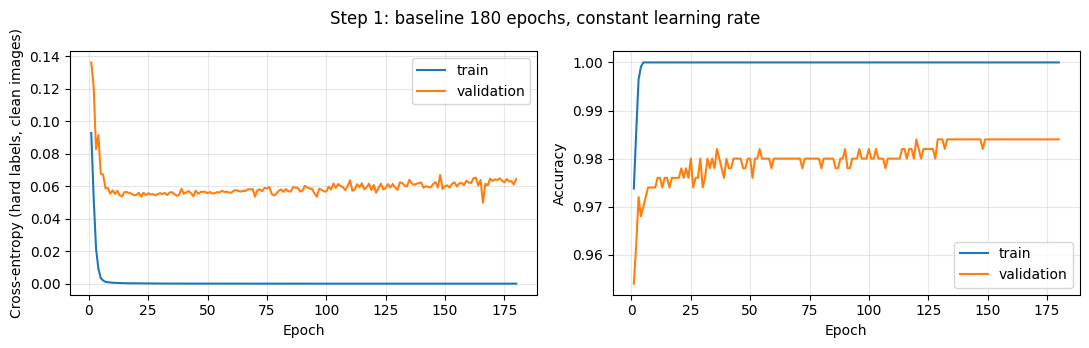

Lowest validation CE: {'epoch': 166, 'lr': 0.001, 'train_loss': 2.9831391940307286e-07, 'train_accuracy': 1.0, 'val_loss': 0.049771446228027344, 'val_accuracy': 0.984}
Final epoch: {'epoch': 180, 'lr': 0.001, 'train_loss': 8.326104175972028e-08, 'train_accuracy': 1.0, 'val_loss': 0.06434855651855469, 'val_accuracy': 0.984}


In [3]:
baseline_record, baseline_model = train_one(
    seed=0,epochs=180,cosine=False,legacy=True)
h1 = baseline_record["history"]
plot_history(h1,"Step 1: baseline 180 epochs, constant learning rate")
best = min(h1,key=lambda r:r["val_loss"])
print("Lowest validation CE:",best)
print("Final epoch:",h1[-1])
# Dựa vào đồ thị thực tế để cập nhật câu trả lời; không suy ra onset từ argmin đơn lẻ.


**A.** Train accuracy đạt 100% từ trước epoch 20 và train loss giảm gần 0; validation loss có xu hướng tăng nhẹ sau giai đoạn đầu, cho thấy overfit nhẹ. Ở epoch 180, validation accuracy là 98,4% và CE là 0,06435. Do loss dao động và có điểm giảm đột ngột ở epoch 166, em không coi argmin là thời điểm bắt đầu overfit chính xác.


---
## Step 2 — RQ: Can we stop the model from memorising?
Your baseline memorises the training set. Find a way (or two) to make it generalise better *without adding data*, and test it.

**Q.** What did you try, why should it work, and did it?

Các so sánh sau dùng cosine 60 epoch; baseline cũng chạy với cùng lịch và thứ tự batch theo seed. Báo checkpoint cuối, không chọn epoch tốt nhất bằng validation. Baseline Step 1 là lượt chẩn đoán LR cố định riêng.


seed=0, epoch=1, train=94.378%, val=93.400%
seed=0, epoch=20, train=100.000%, val=98.200%
seed=0, epoch=40, train=100.000%, val=98.000%
seed=0, epoch=60, train=100.000%, val=98.200%
seed=1, epoch=1, train=95.956%, val=95.400%
seed=1, epoch=20, train=100.000%, val=98.400%
seed=1, epoch=40, train=100.000%, val=98.600%
seed=1, epoch=60, train=100.000%, val=98.600%
seed=2, epoch=1, train=97.622%, val=95.800%
seed=2, epoch=20, train=100.000%, val=98.400%
seed=2, epoch=40, train=100.000%, val=98.400%
seed=2, epoch=60, train=100.000%, val=98.600%
seed=0, epoch=1, train=91.867%, val=89.200%
seed=0, epoch=20, train=100.000%, val=98.400%
seed=0, epoch=40, train=100.000%, val=98.800%
seed=0, epoch=60, train=100.000%, val=98.600%
seed=1, epoch=1, train=97.556%, val=94.600%
seed=1, epoch=20, train=100.000%, val=98.800%
seed=1, epoch=40, train=100.000%, val=99.200%
seed=1, epoch=60, train=100.000%, val=99.200%
seed=2, epoch=1, train=96.978%, val=93.800%
seed=2, epoch=20, train=100.000%, val=98.600%


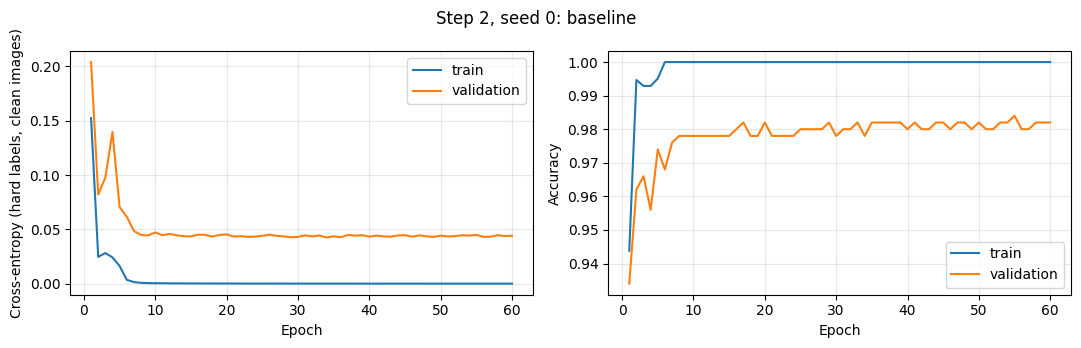

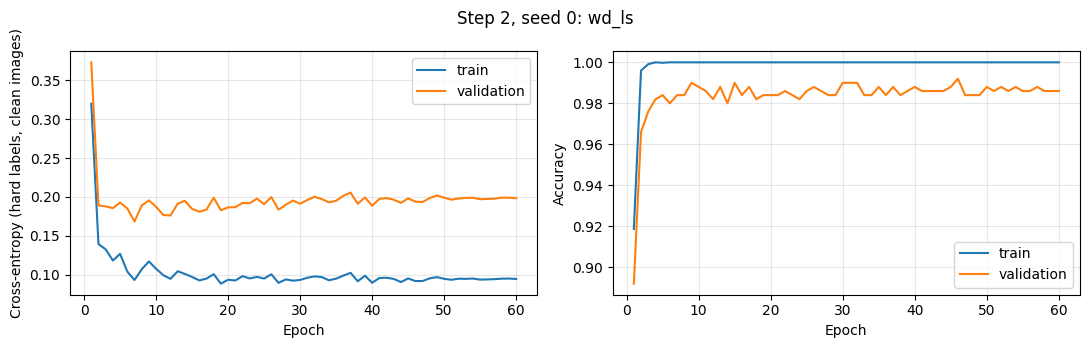

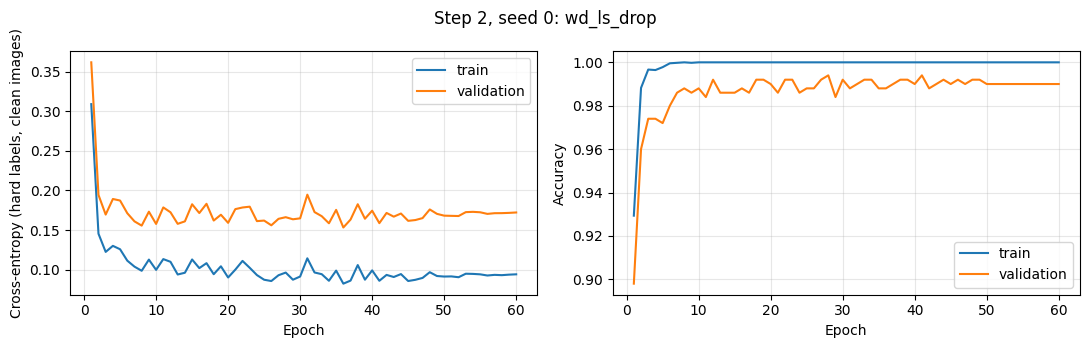

In [5]:
step2_cfg = {
    "baseline": {},
    "wd_ls": dict(wd=.05,ls=.1),
    "wd_ls_drop": dict(wd=.05,ls=.1,dropout=.5),
}
step2 = {name:run_three(**cfg) for name,cfg in step2_cfg.items()}
table(step2)
for name, rows in step2.items():
    plot_history(rows[0]["history"],"Step 2, seed 0: "+name)


**A.** Em thử AdamW weight decay 0,05 và label smoothing 0,1, sau đó thêm dropout 0,5. Accuracy trung bình ± SD lần lượt là baseline 98,47% ± 0,19; WD + LS 99,00% ± 0,28; thêm dropout 99,20% ± 0,16. Đây là cải thiện trên validation trong ba seed, chưa chứng minh ưu thế tổng quát; CE không nhất thiết xếp hạng giống accuracy khi có smoothing.


---
## Step 3 — RQ: Does the architecture matter when data is scarce?
Change something in the design of your CNN and see how it affects generalisation.

**Q.** What did you change, and what did you learn from it?

In [6]:
step3 = {"w32_flatten": step2["baseline"]}
for head,name in (("pool3","w32_pool3"),("gap","w32_gap")):
    step3[name] = run_three(head=head)
for name, rows in step3.items():
    print(name,"parameters:",rows[0]["parameters"])
table(step3)


seed=0, epoch=1, train=94.778%, val=95.400%
seed=0, epoch=20, train=100.000%, val=98.200%
seed=0, epoch=40, train=100.000%, val=98.400%
seed=0, epoch=60, train=100.000%, val=98.200%
seed=1, epoch=1, train=83.778%, val=83.800%
seed=1, epoch=20, train=100.000%, val=98.800%
seed=1, epoch=40, train=100.000%, val=98.600%
seed=1, epoch=60, train=100.000%, val=98.800%
seed=2, epoch=1, train=92.733%, val=91.800%
seed=2, epoch=20, train=100.000%, val=98.800%
seed=2, epoch=40, train=100.000%, val=98.800%
seed=2, epoch=60, train=100.000%, val=98.800%
seed=0, epoch=1, train=77.778%, val=78.600%
seed=0, epoch=20, train=99.978%, val=94.200%
seed=0, epoch=40, train=100.000%, val=96.200%
seed=0, epoch=60, train=100.000%, val=96.400%
seed=1, epoch=1, train=76.022%, val=76.200%
seed=1, epoch=20, train=100.000%, val=96.800%
seed=1, epoch=40, train=100.000%, val=97.000%
seed=1, epoch=60, train=100.000%, val=97.200%
seed=2, epoch=1, train=75.889%, val=74.200%
seed=2, epoch=20, train=100.000%, val=96.000%
s

**A.** Giữ backbone cố định, flatten đạt 98,47% ± 0,19 với 155.850 tham số; pool3 đạt 98,60% ± 0,28 với 104.650; GAP đạt 96,53% ± 0,50 với 94.410. Pool3 giảm khoảng 33% tham số và có accuracy gần flatten, còn GAP thấp hơn. Kết quả phù hợp với khả năng bố cục thô hữu ích, nhưng chưa tách được tác động của bố cục, capacity và tối ưu hóa.


---
## Step 4 — RQ: Can we get more out of the data we have?
You only have 4,500 images. Find a way to make each image count for more, and test it.

**Q.** What did you try, and did it help? Is there anything that would *not* be safe to do with digits?

seed=0, epoch=1, train=93.711%, val=92.600%
seed=0, epoch=20, train=99.844%, val=98.600%
seed=0, epoch=40, train=100.000%, val=99.600%
seed=0, epoch=60, train=100.000%, val=99.400%
seed=1, epoch=1, train=95.089%, val=93.800%
seed=1, epoch=20, train=99.911%, val=99.000%
seed=1, epoch=40, train=100.000%, val=100.000%
seed=1, epoch=60, train=100.000%, val=99.800%
seed=2, epoch=1, train=96.578%, val=95.000%
seed=2, epoch=20, train=99.933%, val=99.600%
seed=2, epoch=40, train=100.000%, val=99.800%
seed=2, epoch=60, train=100.000%, val=99.600%
Recipe                                 Mean ± SD (pp)   Seeds 0 / 1 / 2
wd_ls                             99.00% ± 0.28   98.60 / 99.20 / 99.20
wd_ls_shift                       99.60% ± 0.16   99.40 / 99.80 / 99.60


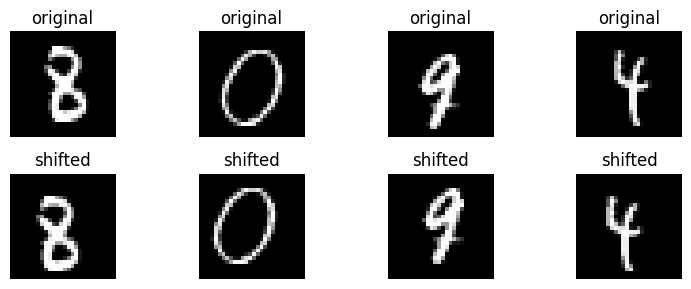

Paired seed 0 b 1 c 5 p 0.21875
Paired seed 1 b 1 c 4 p 0.375
Paired seed 2 b 0 c 2 p 0.5


In [7]:
step4 = {
    "wd_ls": step2["wd_ls"],
    "wd_ls_shift": run_three(wd=.05,ls=.1,shift=True),
}
table(step4)
# Minh họa chỉ dùng ảnh train, không dùng test.
plt.figure(figsize=(8,3))
for i in range(8):
    plt.subplot(2,4,i+1)
    image = x_tr[i:i+1] if i<4 else rand_shift(x_tr[i-4:i-3])
    plt.imshow(image[0,0],cmap="gray",vmin=0,vmax=1)
    plt.title("original" if i<4 else "shifted"); plt.axis("off")
plt.tight_layout(); plt.show()

# Exact two-sided McNemar per seed from NEW checkpoints; không gộp seed.
@torch.no_grad()
def correct_mask(record):
    cfg = record["config"]
    model = CNN(width=cfg["width"],head=cfg["head"],dropout=cfg["dropout"],
                mean=cfg["mean"],std=cfg["std"]).to(DEV)
    model.load_state_dict(torch.load(record["checkpoint"],map_location=DEV,weights_only=True))
    model.eval()
    pred = torch.cat([model(x.to(DEV)).argmax(1).cpu() for x in x_va.split(512)])
    return pred==y_va
for a,b in zip(step4["wd_ls"],step4["wd_ls_shift"]):
    ca,cb = correct_mask(a),correct_mask(b)
    b_count,c_count = int((ca & ~cb).sum()),int((~ca & cb).sum())
    total = b_count+c_count
    p = min(1.,2*sum(math.comb(total,k) for k in range(min(b_count,c_count)+1))/2**total) if total else 1.
    print("Paired seed",a["seed"],"b",b_count,"c",c_count,"p",p)


# **Bổ sung: learning curve:**
So WD + LS có/không dịch trên cùng subset cân bằng. Mỗi seed chọn một chuỗi subset lồng nhau từ train; validation giữ nguyên. 60 epoch ở các mức n không đồng nghĩa cùng số gradient update.

seed=0, epoch=1, train=43.000%, val=30.000%
seed=0, epoch=20, train=100.000%, val=81.000%
seed=0, epoch=40, train=100.000%, val=83.800%
seed=0, epoch=60, train=100.000%, val=83.800%
seed=1, epoch=1, train=31.000%, val=22.600%
seed=1, epoch=20, train=100.000%, val=83.200%
seed=1, epoch=40, train=100.000%, val=85.400%
seed=1, epoch=60, train=100.000%, val=85.000%
seed=2, epoch=1, train=55.000%, val=44.200%
seed=2, epoch=20, train=100.000%, val=81.400%
seed=2, epoch=40, train=100.000%, val=84.800%
seed=2, epoch=60, train=100.000%, val=85.000%
10 False [83.8, 85.0, 85.0]
seed=0, epoch=1, train=31.000%, val=24.800%
seed=0, epoch=20, train=100.000%, val=88.000%
seed=0, epoch=40, train=100.000%, val=91.600%
seed=0, epoch=60, train=100.000%, val=92.000%
seed=1, epoch=1, train=22.000%, val=18.200%
seed=1, epoch=20, train=100.000%, val=87.400%
seed=1, epoch=40, train=100.000%, val=90.400%
seed=1, epoch=60, train=100.000%, val=90.800%
seed=2, epoch=1, train=32.000%, val=29.000%
seed=2, epoch=20, 

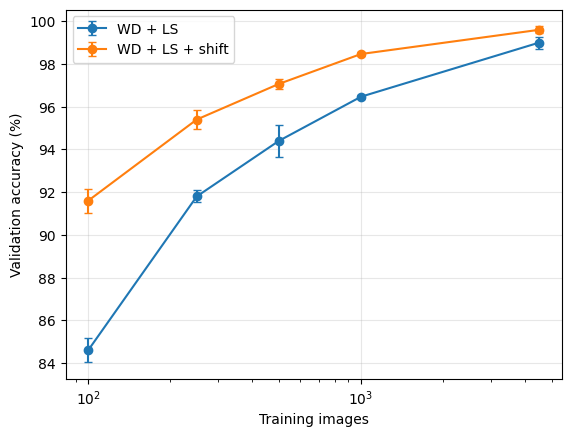

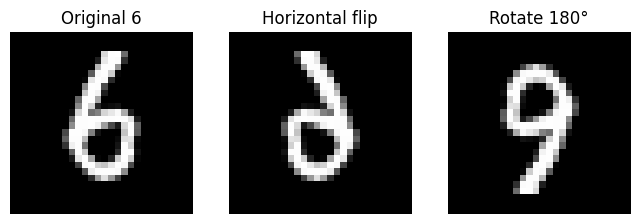

In [8]:
curve = {}
for count in (10,25,50,100,450):
    for aug in (False,True):
        if count==450:
            curve[(count,aug)] = step4["wd_ls_shift" if aug else "wd_ls"]
            continue
        rows = []
        for seed in (0,1,2):
            # Cùng subset giữa hai recipe và lồng nhau theo count.
            g = torch.Generator().manual_seed(seed)
            selected = []
            for k in range(10):
                ids = torch.nonzero(y_tr==k).squeeze(1)
                selected.append(ids[torch.randperm(len(ids),generator=g)[:count]])
            ids = torch.cat(selected)
            r,_ = train_one(seed=seed,wd=.05,ls=.1,shift=aug,
                            data=(x_tr[ids],y_tr[ids]))
            rows.append(r)
        curve[(count,aug)] = rows
        print(count,aug,[round(r["accuracy"]*100,2) for r in rows])
for aug,label in ((False,"WD + LS"),(True,"WD + LS + shift")):
    ns = [10,25,50,100,450]
    a = [np.array([r["accuracy"] for r in curve[(count,aug)]])*100 for count in ns]
    plt.errorbar(np.array(ns)*10,[v.mean() for v in a],
                 yerr=[v.std() for v in a],marker="o",capsize=3,label=label)
plt.xscale("log"); plt.xlabel("Training images")
plt.ylabel("Validation accuracy (%)"); plt.legend(); plt.grid(alpha=.3)
plt.show()
i = int(torch.nonzero(y_tr==6)[0]); digit = x_tr[i,0]
fig, ax = plt.subplots(1,3,figsize=(8,2.5))
for a,x,title in zip(ax,[digit,digit.flip(1),torch.rot90(digit,2)],
                     ["Original 6","Horizontal flip","Rotate 180°"]):
    a.imshow(x,cmap="gray"); a.set_title(title); a.axis("off")
plt.show()


**A.** Dịch zero-fill ±2 px nâng accuracy từ 99,00% ± 0,28 lên 99,60% ± 0,16 và cải thiện cả ba seed. Với validation 500 ảnh, McNemar từng seed có p = 0,21875 / 0,375 / 0,5 nên chưa có bằng chứng mạnh ở ngưỡng 0,05; learning curve cho lợi ích lớn hơn khi ít dữ liệu (100 ảnh: 84,60% lên 91,60%). Lật, xoay lớn hoặc cắt mất nét có nguy cơ đổi nhãn.


---
## Step 5 — Test: Evaluate your best model
Pick your best model on the validation set and evaluate it on the test set **once**.

**Q.** Report the test accuracy. Which idea helped the most?

### Chốt model trước lần test duy nhất

Cell sau chọn recipe theo mean validation accuracy, rồi dùng seed 0 cố định. Mặc định `RUN_STEP5=False` để Bình đọc kết quả validation trước; sau khi chốt, đổi thành `True` và chạy cell đúng một lần. Code khóa SHA-256 checkpoint và tạo dấu mốc trước inference để tránh vô tình chạy test lặp lại trong cùng thư mục.


In [9]:
# Chỉ bật sau khi đã xem validation và chốt recipe.
RUN_STEP5 = False  # Saved output below was generated by the original enabled run.

candidates = {
    "flatten":step2["baseline"],
    "wd_ls":step2["wd_ls"],
    "wd_ls_drop":step2["wd_ls_drop"],
    "pool3":step3["w32_pool3"],
    "gap":step3["w32_gap"],
    "wd_ls_shift":step4["wd_ls_shift"],
}
chosen_name = max(candidates,key=lambda name:
                  np.mean([r["accuracy"] for r in candidates[name]]))
chosen = next(r for r in candidates[chosen_name] if r["seed"]==0)
selection = dict(recipe=chosen_name,config=chosen["config"],
                 checkpoint=chosen["checkpoint"],validation_accuracy=chosen["accuracy"])
print("Selected using validation only:",selection)

if not RUN_STEP5:
    print("Test chưa chạy. Chốt recipe rồi đổi RUN_STEP5=True.")
else:
    checkpoint = Path(chosen["checkpoint"])
    selection["checkpoint_sha256"] = hashlib.sha256(checkpoint.read_bytes()).hexdigest()
    cfg = chosen["config"]
    model = CNN(width=cfg["width"],head=cfg["head"],dropout=cfg["dropout"],
                mean=cfg["mean"],std=cfg["std"]).to(DEV)
    model.load_state_dict(torch.load(checkpoint,map_location=DEV,weights_only=True))
    model.eval()
    # Dấu mốc cố định qua các lần Run All trong cùng thư mục.
    # Nếu đã tồn tại, dừng; không xóa dấu mốc để chọn model khác.
    with Path("HW1_TEST_STARTED.json").open("x") as f:
        json.dump(selection,f,indent=2)
    correct=0; loss_sum=0.; total=len(y_te)
    with torch.no_grad():
        for start in range(0,total,512):
            xb=x_te[start:start+512].to(DEV)
            yb=y_te[start:start+512].to(DEV)
            logits=model(xb)
            correct += int((logits.argmax(1)==yb).sum())
            loss_sum += F.cross_entropy(logits,yb,reduction="sum").item()
    p=correct/total; z=1.959963984540054
    den=1+z*z/total
    center=(p+z*z/(2*total))/den
    half=z*math.sqrt(p*(1-p)/total+z*z/(4*total*total))/den
    result=dict(selection=selection,correct=correct,test_images=total,
                accuracy=p,cross_entropy=loss_sum/total,
                wilson_95=[center-half,center+half])
    Path("HW1_TEST_RESULT.json").write_text(json.dumps(result,indent=2))
    (RUN_DIR/"test_result.json").write_text(json.dumps(result,indent=2))
    print(f"Correct: {correct}/{total}")
    print(f"Test accuracy: {100*p:.4f}%")
    print(f"Wilson 95% CI: [{100*(center-half):.4f}%, {100*(center+half):.4f}%]")


Selected using validation only: {'recipe': 'wd_ls_shift', 'config': {'seed': 0, 'epochs': 60, 'width': 32, 'head': 'flatten', 'wd': 0.05, 'ls': 0.1, 'dropout': 0.0, 'shift': True, 'cosine': True, 'legacy': False, 'n_train': 4500, 'mean': 0.1307, 'std': 0.3081}, 'checkpoint': 'hw1_runs/20261014_030406_544672/9f11bf26c3489d7c.pt', 'validation_accuracy': 0.994}
Correct: 64479/65000
Test accuracy: 99.1985%
Wilson 95% CI: [99.1269%, 99.2642%]


A. Model wd_ls_shift (width 32, head flatten, WD 0.05, LS 0.1, dịch ±2 px), seed 0, checkpoint epoch 60 đạt 64,479/65,000 ảnh đúng, test accuracy 99.1985%, Wilson 95% CI [99.13%, 99.26%] (validation của model này là 99.40%, sát với test). Ý tưởng có bằng chứng giúp nhiều nhất trên validation là dịch ảnh (+0.6 pp trên nền WD + LS, nhất quán ở 3 seed, và lợi ích lớn hơn khi ít dữ liệu); WD + LS cũng giúp +0.5 pp so với baseline. Test chỉ dùng một lần cho model cuối.